# TALLER METODO PROGRAMACION DE COMPROMISO PARA PROBLEMAS MULTIOBJETIVO DISCRETOS
ELECCION CARRO ELECTRICO

Curso: Introducción al Análisis de Decisiones

Universidad Nacional de Colombia, Sede Medellín

Realizado por Profesora Patricia Jaramillo y estudiante Luis José Mejía

Fecha actualización: 19 de Julio de 2026  
Ajuste menor: 20/07 (gráficas)





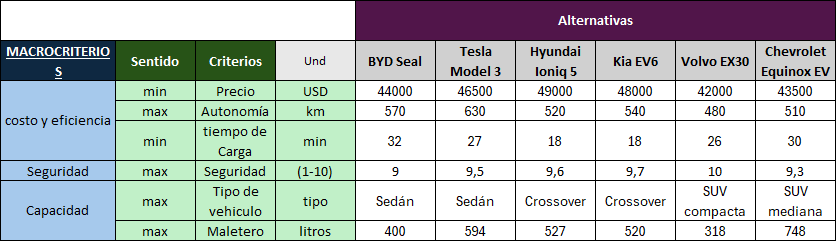

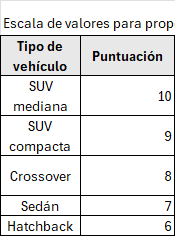

In [1]:
# Se importa la librería numpy para realizar cálculos matemáticos
import numpy as np
# Se importa la librería pandas para manipular tablas
import pandas as pd
from numpy import *
import matplotlib.pyplot as plt


# Crear el DataFrame con los datos de la matriz de consecuencias

# Nombres de las alternativas

# Matriz de consecuencias
data = [
    [-44000, -46500, -49000, -48000, -42000, -43500],      # C1=Precio
    [570, 630, 520, 540, 480, 510],                        # C2=autonomia
    [-32, -27, -18, -18, -26, -30],                        # C3=tiempo de carga
    [9, 9.5, 9.6, 9.7, 10, 9.3],                           # C4=seguridad
    [7, 7, 8, 8, 9, 10],                                   # C5=tipo de vehiculo
    [400, 594, 527, 520, 318, 748],                        # C6=maletero

]

criterios = ['Precio', 'Autonomia', 'Tiempo de carga', 'Seguridad', 'Tipo de vehiculo', 'Maletero']
#

weights = [0.17, 0.17, 0.17, 0.17, 0.17, 0.17]

# Nombres de las alternativas
alternativas = ['BYD_seal', 'Tesla', 'Hyundai', 'Kia', 'Volvo',
           'Chevrolet']

# Crear el DataFrame
matriz_consecuencias = pd.DataFrame(data, index=criterios, columns=alternativas)

# Mostrar el DataFrame
print(matriz_consecuencias)




                  BYD_seal    Tesla  Hyundai      Kia  Volvo  Chevrolet
Precio              -44000 -46500.0 -49000.0 -48000.0 -42000   -43500.0
Autonomia              570    630.0    520.0    540.0    480      510.0
Tiempo de carga        -32    -27.0    -18.0    -18.0    -26      -30.0
Seguridad                9      9.5      9.6      9.7     10        9.3
Tipo de vehiculo         7      7.0      8.0      8.0      9       10.0
Maletero               400    594.0    527.0    520.0    318      748.0


In [2]:
# Normalización

matriz_normalizada = matriz_consecuencias.apply(lambda fila: (fila - fila.min()) / (fila.max() - fila.min()), axis=1)

print("Matriz normalizada por filas (min-max):","\n")
print(matriz_normalizada.round(3))

ideal= matriz_consecuencias.max(axis=1)
peor= matriz_consecuencias.min(axis=1)
print ("\n","Z ideales", "\n")
print (ideal)
print ("\n""Z peores","\n")
print (peor)

Matriz normalizada por filas (min-max): 

                  BYD_seal  Tesla  Hyundai    Kia  Volvo  Chevrolet
Precio               0.714  0.357    0.000  0.143  1.000      0.786
Autonomia            0.600  1.000    0.267  0.400  0.000      0.200
Tiempo de carga      0.000  0.357    1.000  1.000  0.429      0.143
Seguridad            0.000  0.500    0.600  0.700  1.000      0.300
Tipo de vehiculo     0.000  0.000    0.333  0.333  0.667      1.000
Maletero             0.191  0.642    0.486  0.470  0.000      1.000

 Z ideales 

Precio             -42000.0
Autonomia             630.0
Tiempo de carga       -18.0
Seguridad              10.0
Tipo de vehiculo       10.0
Maletero              748.0
dtype: float64

Z peores 

Precio             -49000.0
Autonomia             480.0
Tiempo de carga       -32.0
Seguridad               9.0
Tipo de vehiculo        7.0
Maletero              318.0
dtype: float64


CALCULAR DISTANCIA NORMALIZADA AL IDEAL POR CADA CRITERIO INDEPENDIENTEMENTE

In [3]:

distancia_normalizada = matriz_consecuencias.apply(lambda fila: (fila.max() - fila) / (fila.max() - fila.min()), axis=1)
#Esta matriz es equivalente a 1- matriz_normalizada
print("distancia normalizada", "\n", distancia_normalizada)

distancia_ponderada= distancia_normalizada*weights
print("\n","distancia ponderada", "\n", distancia_ponderada)

distancia normalizada 
                   BYD_seal     Tesla   Hyundai       Kia     Volvo  Chevrolet
Precio            0.285714  0.642857  1.000000  0.857143  0.000000   0.214286
Autonomia         0.400000  0.000000  0.733333  0.600000  1.000000   0.800000
Tiempo de carga   1.000000  0.642857  0.000000  0.000000  0.571429   0.857143
Seguridad         1.000000  0.500000  0.400000  0.300000  0.000000   0.700000
Tipo de vehiculo  1.000000  1.000000  0.666667  0.666667  0.333333   0.000000
Maletero          0.809302  0.358140  0.513953  0.530233  1.000000   0.000000

 distancia ponderada 
                   BYD_seal     Tesla   Hyundai       Kia     Volvo  Chevrolet
Precio            0.048571  0.109286  0.170000  0.145714  0.000000   0.036429
Autonomia         0.068000  0.000000  0.124667  0.102000  0.170000   0.136000
Tiempo de carga   0.170000  0.109286  0.000000  0.000000  0.097143   0.145714
Seguridad         0.170000  0.085000  0.068000  0.051000  0.000000   0.119000
Tipo de vehiculo

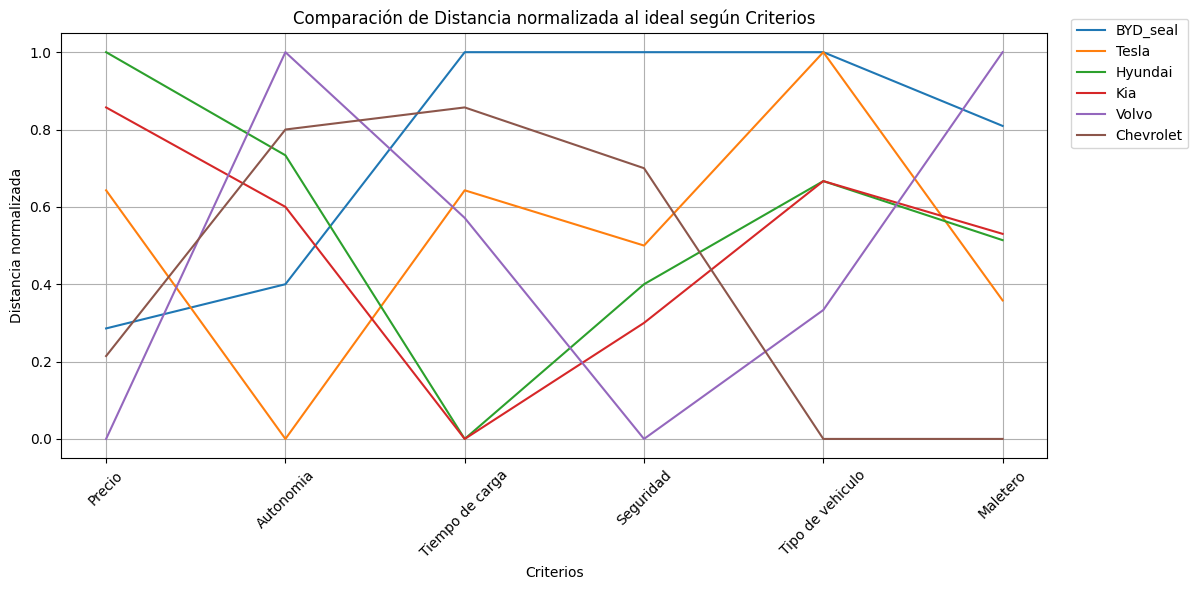

In [4]:
# Crear el gráfico
plt.figure(figsize=(12, 6))

# Transponer el DataFrame: filas = alternativas, columnas = criterios
distancia_normalizada_transpuesta = distancia_normalizada.T
# Graficar una línea por cada alternativa
for alt in distancia_normalizada_transpuesta.index:
    plt.plot(distancia_normalizada_transpuesta.columns, distancia_normalizada_transpuesta.loc[alt], label=alt)

# Personalizar el gráfico
plt.title("Comparación de Distancia normalizada al ideal según Criterios")
plt.xlabel("Criterios")
plt.ylabel("Distancia normalizada")
plt.xticks(rotation=45)
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1.05), ncol=1)
plt.grid(True)
plt.tight_layout()

# Mostrar el gráfico
plt.show()



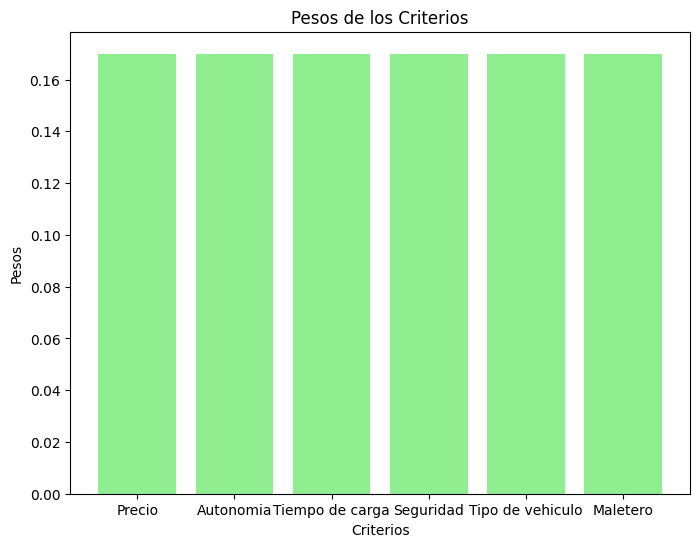

In [5]:
# Gráfico de barras para los pesos de los criterios
plt.figure(figsize=(8, 6))
plt.bar(criterios, weights, color='lightgreen')
plt.xlabel('Criterios')
plt.ylabel('Pesos')
plt.title('Pesos de los Criterios')
plt.show()

# PROGRAMACION DE COMPROMISO METRICA UNO (MANHATTAN):

Distancia Manhatan al ideal 
 BYD_seal     0.764153
Tesla        0.534455
Hyundai      0.563372
Kia          0.502187
Volvo        0.493810
Chevrolet    0.437143
dtype: float64
la mejor alternativa es segun metrica uno:  Chevrolet


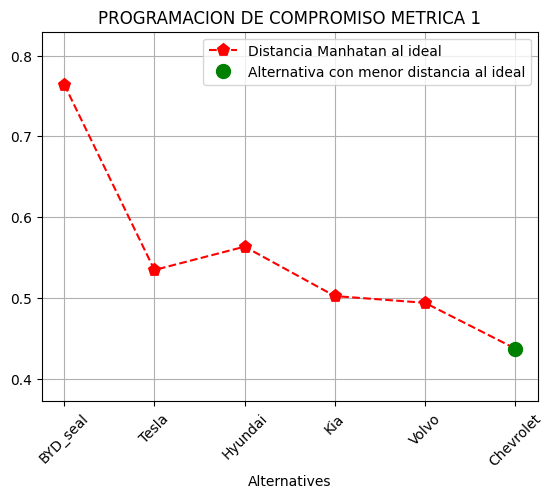

In [12]:
p=1

dis_manhatan = (sum(distancia_ponderada, 0))

print("Distancia Manhatan al ideal","\n", dis_manhatan)

# Encontrar la alternativa con menor distancia al ideal
min_manhatan_index = argmin(dis_manhatan)
min_manhatan_value = dis_manhatan.iloc[min_manhatan_index]

print( "la mejor alternativa es segun metrica uno: ",alternativas[min_manhatan_index ])

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dis_manhatan, 'p--', color = 'red',
markeredgewidth = 2, markersize = 8)
plt.plot(q[min_manhatan_index], min_manhatan_value, 'o', color='green', markersize=10, label=f'Min dideal: {min_manhatan_value:.4f}')


plt.title(f'PROGRAMACION DE COMPROMISO METRICA {p}')
plt.legend(['Distancia Manhatan al ideal', 'Alternativa con menor distancia al ideal'])

plt.xticks(q, alternativas, rotation=45)

# Dynamic Y-axis adjustment
min_val = dis_manhatan.min()
max_val = dis_manhatan.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternatives')
plt.grid(True)
plt.show()


# PROGRAMACION DE COMPROMISO METRICA 2 (EUCLIDIANA):



Distancia Euclidiana al ideal 
 BYD_seal     0.335577
Tesla        0.252425
Hyundai      0.263712
Kia          0.234962
Volvo        0.265420
Chevrolet    0.234982
dtype: float64

 la mejor alternativa es segun metrica dos:  Kia


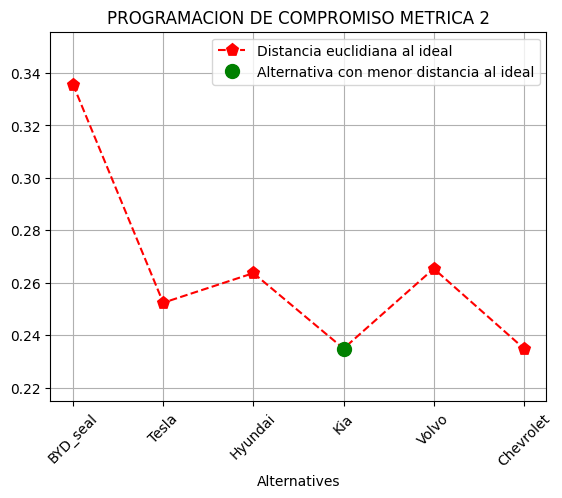

In [13]:
p=2

dis_euclidiana = (sum(distancia_ponderada**p, 0))**(1/p)

print("Distancia Euclidiana al ideal", "\n", dis_euclidiana)


# Encontrar la alternativa con menor distancia al ideal
min_euclidiana_index = argmin(dis_euclidiana)
min_euclidiana_value = dis_euclidiana.iloc[min_euclidiana_index]

print("\n", "la mejor alternativa es segun metrica dos: ",alternativas[min_euclidiana_index ])

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dis_euclidiana, 'p--', color = 'red',
markeredgewidth = 2, markersize = 8)
plt.plot(q[min_euclidiana_index], min_euclidiana_value, 'o', color='green', markersize=10, label=f'Min dideal: {min_euclidiana_value:.4f}')


plt.title(f'PROGRAMACION DE COMPROMISO METRICA {p}')
plt.legend(['Distancia euclidiana al ideal', 'Alternativa con menor distancia al ideal'])

plt.xticks(q, alternativas, rotation=45)

# Dynamic Y-axis adjustment
min_val = dis_euclidiana.min()
max_val = dis_euclidiana.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternatives')
plt.grid(True)
plt.show()

# PROGRAMACION DE COMPROMISO METRICA INFINTO (Chebyshev):

Distancia Chebyshev al ideal 
 BYD_seal     0.170000
Tesla        0.170000
Hyundai      0.170000
Kia          0.145714
Volvo        0.170000
Chevrolet    0.145714
dtype: float64

 la mejor alternativa es segun metrica infinito:  Kia


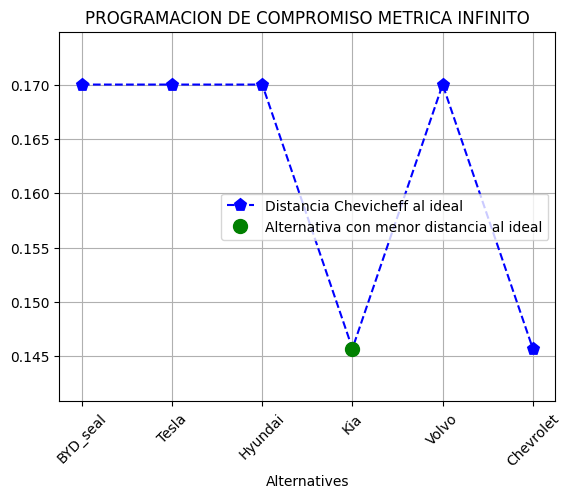

In [14]:
#Para p = infinito, distancia = max (w (Zideal- Zij)(Zideal.Zpeor))

dideal_inf=(max(distancia_ponderada, 0))

print("Distancia Chebyshev al ideal","\n", dideal_inf)

# Encontrar la alternativa con menor distancia al ideal
min_dideal_indexI = argmin(dideal_inf)
min_dideal_valueI = dideal_inf.iloc[min_dideal_indexI]

print( "\n","la mejor alternativa es segun metrica infinito: ",alternativas[min_dideal_indexI ])

q = [i + 1 for i in range(len(alternativas))]
plt.plot(q, dideal_inf, 'p--', color = 'blue',markeredgewidth = 2, markersize = 8)

plt.plot(q[min_dideal_indexI], min_dideal_valueI, 'o', color='green', markersize=10, label=f'Min dideal: {min_dideal_valueI:.4f}')
plt.title(f'PROGRAMACION DE COMPROMISO METRICA INFINITO')
plt.legend(['Distancia Chevicheff al ideal', 'Alternativa con menor distancia al ideal'])
plt.xticks(q,alternativas, rotation=45)

# Dynamic Y-axis adjustment
min_val = dideal_inf.min()
max_val = dideal_inf.max()
range_val = max_val - min_val
margin = range_val * 0.2
new_ymin = np.maximum(0, min_val - margin)
new_ymax = max_val + margin
plt.ylim(new_ymin, new_ymax)

plt.xlabel('Alternatives')
plt.grid(True)
plt.show()